In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [ ]:
uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())
print("\nColumn Names:")
print(df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())

Saving BookMyShow_Weka_Classification_Final.csv to BookMyShow_Weka_Classification_Final.csv
Dataset Shape: (20000, 14)

First 5 Records:
   total_tickets  ticket_price  total_amount  available_seats payment_method  \
0              3        363.67       1091.01              179         Wallet   
1              1        364.32        364.32              208    Credit Card   
2              2        187.61        375.22               58            UPI   
3              6        120.11        720.66               95            UPI   
4              1        371.18        371.18              142    Credit Card   

   booking_hour  booking_day movie_genre movie_language  movie_rating  \
0            16            5      Action          Hindi           6.8   
1            16            3     Romance         Telugu           9.3   
2            19            5      Sci-Fi        Bengali           6.7   
3             0            5      Action        Kannada           6.8   
4            18  

In [ ]:
features = [
    "total_tickets",
    "ticket_price",
    "available_seats",
    "booking_hour",
    "booking_day",
    "movie_rating",
    "duration"
]

X = df[features].copy()

print("Selected Features:")
print(X.head())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nStandardized Data Shape:", X_scaled.shape)

Selected Features:
   total_tickets  ticket_price  available_seats  booking_hour  booking_day  \
0              3        363.67              179            16            5   
1              1        364.32              208            16            3   
2              2        187.61               58            19            5   
3              6        120.11               95             0            5   
4              1        371.18              142            18            4   

   movie_rating  duration  
0           6.8       127  
1           9.3       123  
2           6.7       194  
3           6.8       187  
4           8.0       151  

Standardized Data Shape: (20000, 7)


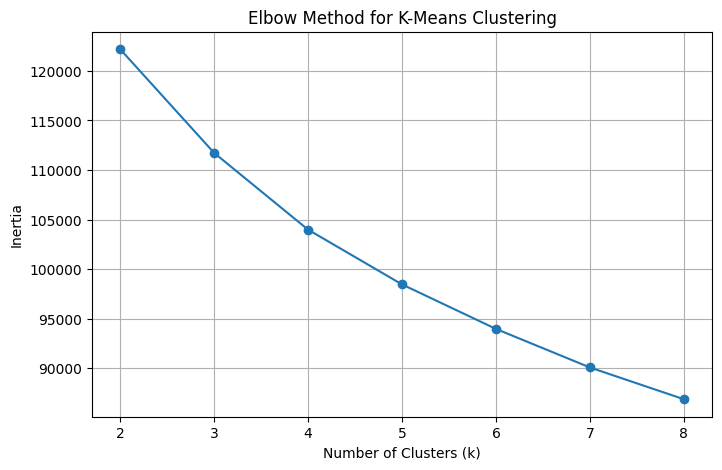

In [ ]:
inertias = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=10,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
k = 4

kmeans = KMeans(
    n_clusters=k,
    random_state=10,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)
df["Cluster"] = clusters

print("Number of Clusters:", k)
print("\nCluster Counts:")
print(df["Cluster"].value_counts().sort_index())

Number of Clusters: 4

Cluster Counts:
Cluster
0    5912
1    3976
2    5052
3    5060
Name: count, dtype: int64


In [ ]:
silhouette = silhouette_score(X_scaled, clusters)
inertia = kmeans.inertia_
db_index = davies_bouldin_score(X_scaled, clusters)

print("Silhouette Score:", round(silhouette, 4))
print("Inertia:", round(inertia, 4))
print("Davies-Bouldin Index:", round(db_index, 4))

Silhouette Score: 0.108
Inertia: 103982.8381
Davies-Bouldin Index: 2.1923


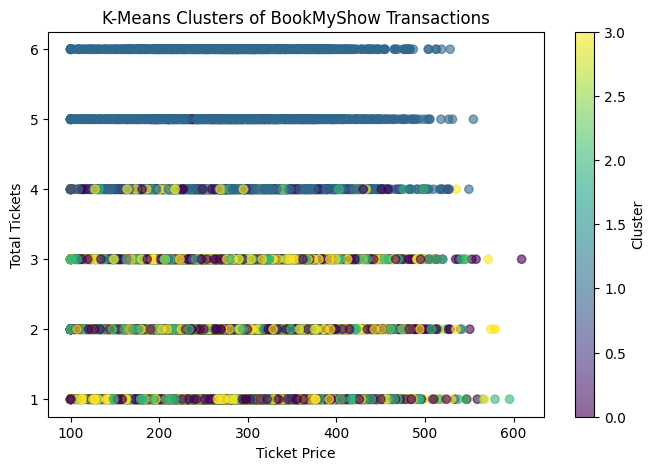

In [ ]:
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    df["ticket_price"],
    df["total_tickets"],
    c=clusters,
    cmap="viridis",
    alpha=0.6
)

plt.xlabel("Ticket Price")
plt.ylabel("Total Tickets")
plt.title("K-Means Clusters of BookMyShow Transactions")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [ ]:
cluster_profile = df.groupby("Cluster")[features].mean().round(2)

print("Mean Feature Values for Each Cluster:")
print(cluster_profile)

Mean Feature Values for Each Cluster:
         total_tickets  ticket_price  available_seats  booking_hour  \
Cluster                                                               
0                 2.04        277.22           142.87          9.09   
1                 4.71        280.76            84.17         11.65   
2                 2.01        279.01           123.67          6.73   
3                 2.08        281.66            78.54         18.91   

         booking_day  movie_rating  duration  
Cluster                                       
0               2.16          6.70    144.85  
1               3.88          6.80    145.02  
2               5.76          6.92    145.97  
3               4.47          6.77    144.59  
